# DS605 Lab 7 - Image Representation, PCA, Eigenfaces and Face Recognition
**Dataset:** AT&T (ORL) Database of Faces - 40 subjects x 10 images, 112 x 92 grayscale.

**Workflow:** Images -> Grayscale pixel matrix -> Flatten -> Mean centering -> PCA / SVD -> Explained variance -> Eigenfaces -> Reduced representation -> Reconstruction -> Similarity matching -> ML classification

**Rule followed:** all PCA / eigenface maths uses plain NumPy (`np.linalg.eigh`, `np.linalg.svd`). Scikit-learn is imported only in Part D for the classifiers / model selection.

In [1]:
import os, re, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image          # image *reading* only

warnings.filterwarnings("ignore")
SEED = 42
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 100, "image.cmap": "gray"})

# ---- dataset location: env var > your local path > ./archive > ./data
DATA_DIR_CANDIDATES = [
    os.environ.get("ORL_DATA_DIR"),
    r"C:\Users\HP\Documents\DS605-Fundamentals-of-Machine-Learning\LAB07\archive",
    "archive", "data",
]
DATA_DIR = next((Path(p) for p in DATA_DIR_CANDIDATES if p and Path(p).is_dir()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Dataset folder not found. Set DATA_DIR_CANDIDATES or the ORL_DATA_DIR env variable.")
print("Using dataset folder:", DATA_DIR)

FIG_DIR, RES_DIR = Path("figures"), Path("results")
FIG_DIR.mkdir(exist_ok=True); RES_DIR.mkdir(exist_ok=True)

def savefig(fig, name):
    fig.savefig(FIG_DIR / name, bbox_inches="tight", dpi=150)
    plt.show()

Using dataset folder: C:\Users\HP\Documents\DS605-Fundamentals-of-Machine-Learning\LAB07\archive


## Part A - Image representation
### A1. Read images as grayscale matrices
Every image file under the dataset folder is read (`.pgm` for ORL; other common formats also handled). The subject label is the name of the parent folder (`s1 ... s40`).

In [2]:
EXT = {".pgm", ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

def natural_key(s):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", str(s))]

def load_dataset(root):
    root = Path(root)
    files = sorted([p for p in root.rglob("*") if p.suffix.lower() in EXT],
                   key=lambda p: natural_key(p.relative_to(root)))
    if not files:
        raise FileNotFoundError(f"No image files found under {root}")
    raw, names = [], []
    for p in files:
        raw.append(np.array(Image.open(p).convert("L")))      # grayscale uint8 matrix
        # label = parent folder (s1..s40); if images sit directly in root use filename prefix
        names.append(p.parent.name if p.parent != root else re.split(r"[_\-\.]", p.stem)[0])
    # make sure all images share one size
    shapes = pd.Series([a.shape for a in raw]).value_counts()
    H, W = shapes.index[0]
    raw = [a if a.shape == (H, W) else np.array(Image.fromarray(a).resize((W, H))) for a in raw]
    classes = sorted(set(names), key=natural_key)
    y = np.array([classes.index(n) for n in names])
    return np.stack(raw), y, classes, files

images, y, class_names, files = load_dataset(DATA_DIR)
N, H, Wd = images.shape
D = H * Wd
print(f"images array : {images.shape}  dtype={images.dtype}")
print(f"image size   : {H} x {Wd}  ->  {D} pixels per image")
print(f"subjects     : {len(class_names)}   images/subject: {np.bincount(y).min()}-{np.bincount(y).max()}")
print(f"intensity    : min={images.min()}  max={images.max()}  mean={images.mean():.1f}  std={images.std():.1f}")
print("\nTop-left 6x6 patch of the first image (raw pixel matrix):\n", images[0, :6, :6])

images array : (400, 112, 92)  dtype=uint8
image size   : 112 x 92  ->  10304 pixels per image
subjects     : 40   images/subject: 10-10
intensity    : min=0  max=251  mean=112.6  std=49.9

Top-left 6x6 patch of the first image (raw pixel matrix):
 [[48 49 45 47 49 57]
 [45 52 39 46 56 45]
 [45 50 42 51 51 45]
 [49 46 47 47 50 47]
 [46 46 47 48 48 44]
 [47 45 48 51 44 35]]


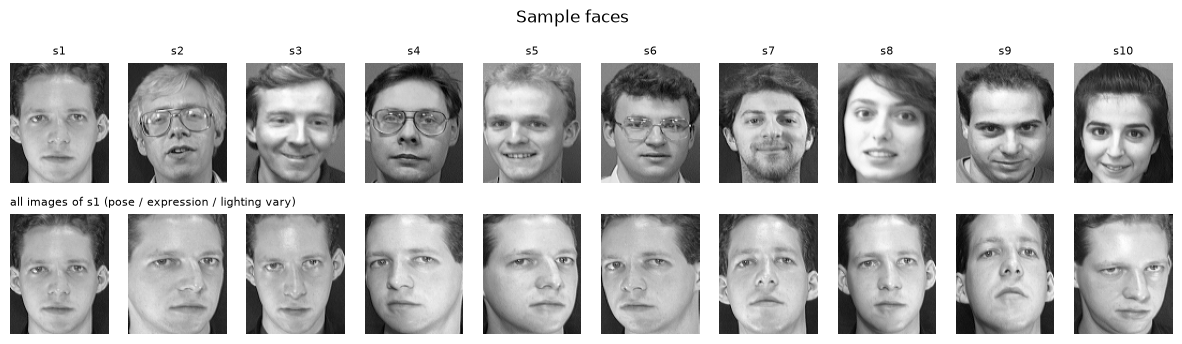

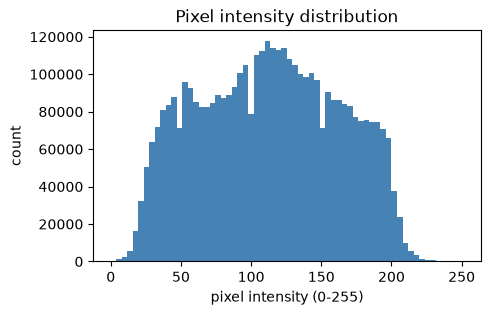

In [3]:
fig, axes = plt.subplots(2, 10, figsize=(15, 3.6))
for j, ax in enumerate(axes[0]):                       # first image of 10 different subjects
    i = np.flatnonzero(y == j)[0]; ax.imshow(images[i]); ax.set_title(class_names[j], fontsize=8); ax.axis("off")
sid = 0
for j, ax in enumerate(axes[1]):                       # all 10 images of subject 1
    i = np.flatnonzero(y == sid)[j]; ax.imshow(images[i]); ax.axis("off")
axes[1, 0].set_title(f"all images of {class_names[sid]} (pose / expression / lighting vary)", fontsize=8, loc="left")
fig.suptitle("Sample faces", y=1.02); savefig(fig, "01_sample_faces.png")

fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(images.ravel(), bins=64, color="steelblue"); ax.set_xlabel("pixel intensity (0-255)"); ax.set_ylabel("count")
ax.set_title("Pixel intensity distribution"); savefig(fig, "02_intensity_histogram.png")

### A2. Flatten, scale and build the image matrix
Each image becomes a row vector of length H*W and intensities are scaled to [0, 1]. The result is the data matrix **X** (N x D) with the label vector **y**.

In [4]:
X = images.reshape(N, -1).astype(np.float64) / 255.0
print("Image matrix X:", X.shape, " labels y:", y.shape, " range:", X.min(), "-", X.max())

Image matrix X: (400, 10304)  labels y: (400,)  range: 0.0 - 0.984313725490196


### A3. Reproducible stratified train/test split
For every subject, 2 randomly chosen images go to the test set and the other 8 to the training set (seeded RNG, so the split is identical on every run and every subject is in both sets). Implemented in NumPy.

In [5]:
def stratified_split(y, n_test_per_class=2, seed=SEED):
    rg = np.random.default_rng(seed)
    tr, te = [], []
    for c in np.unique(y):
        idx = np.flatnonzero(y == c); rg.shuffle(idx)
        assert len(idx) > n_test_per_class, "not enough images per subject"
        te += idx[:n_test_per_class].tolist(); tr += idx[n_test_per_class:].tolist()
    return np.sort(tr), np.sort(te)

tr_idx, te_idx = stratified_split(y)
X_train, y_train, X_test, y_test = X[tr_idx], y[tr_idx], X[te_idx], y[te_idx]
print("train:", X_train.shape, " test:", X_test.shape)
assert set(y_train) == set(y_test) == set(np.unique(y)), "every subject must appear in both sets"
print("All", len(np.unique(y)), "subjects appear in both train and test.")
np.savez_compressed(RES_DIR / "split_indices.npz", train=tr_idx, test=te_idx)

train: (320, 10304)  test: (80, 10304)
All 40 subjects appear in both train and test.


## Part B - PCA, eigenfaces and compression
### B1. Mean face and centering

centred data mean (should be ~0): 1.4703516182379417e-15


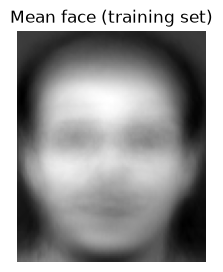

In [6]:
n, d = X_train.shape
mean_face = X_train.mean(axis=0)
A = X_train - mean_face                      # centred training data (n x d)
print("centred data mean (should be ~0):", np.abs(A.mean(axis=0)).max())

fig, ax = plt.subplots(figsize=(2.6, 3)); ax.imshow(mean_face.reshape(H, Wd)); ax.axis("off")
ax.set_title("Mean face (training set)"); savefig(fig, "03_mean_face.png")

### B2. Principal directions - covariance eigendecomposition vs SVD
**Method 1 - covariance / eigendecomposition.** With d = 10,304 pixels the full covariance matrix is d x d (~850 MB), so we use the classic Turk-Pentland "dual" trick: the nonzero eigenvalues of `C = A^T A/(n-1)` equal those of the small `n x n` matrix `G = A A^T/(n-1)`, and if `G v = l v` then `u = A^T v` (normalised) is the matching eigenvector of `C`. The result is mathematically identical to decomposing the full covariance. A direct full-covariance check on downsampled images follows below.

**Method 2 - SVD.** `A = U S V^T`; the rows of `V^T` are the principal directions and the eigenvalues are `S^2/(n-1)`.

In [7]:
# ---------- Method 1: eigendecomposition of the covariance (dual form)
t0 = time.perf_counter()
G = (A @ A.T) / (n - 1)
ev_cov, V = np.linalg.eigh(G)                         # ascending
order = np.argsort(ev_cov)[::-1]
ev_cov, V = ev_cov[order], V[:, order]
r = int(np.sum(ev_cov > 1e-10 * ev_cov[0]))           # rank (<= n-1 after centring)
ev_cov, V = ev_cov[:r], V[:, :r]
W_cov = A.T @ V
W_cov /= np.linalg.norm(W_cov, axis=0)                # d x r, unit-length eigenfaces
t_cov = time.perf_counter() - t0

# ---------- Method 2: SVD
t0 = time.perf_counter()
U, S, Vt = np.linalg.svd(A, full_matrices=False)
W_svd = Vt[:r].T                                      # d x r
ev_svd = (S[:r] ** 2) / (n - 1)
t_svd = time.perf_counter() - t0

cos = np.abs((W_cov * W_svd).sum(axis=0))             # |cos angle| between matching directions
print(f"rank r = {r}")
print(f"time  : eigendecomposition {t_cov*1000:.0f} ms   |   SVD {t_svd*1000:.0f} ms")
print(f"max |eigenvalue difference|              : {np.abs(ev_cov - ev_svd).max():.3e}")
print(f"|cos| between directions  min / median   : {cos.min():.6f} / {np.median(cos):.6f}")
print(f"first 50 components with |cos| > 0.9999  : {(cos[:50] > 0.9999).sum()} / 50")

rank r = 319
time  : eigendecomposition 509 ms   |   SVD 5191 ms
max |eigenvalue difference|              : 1.279e-13
|cos| between directions  min / median   : 1.000000 / 1.000000
first 50 components with |cos| > 0.9999  : 50 / 50


In [8]:
# Sanity check of the *full* covariance route on 4x-downsampled images (644 dims -> full 644x644 covariance is cheap)
Xs = A.reshape(n, H, Wd)[:, ::4, ::4].reshape(n, -1)
Cfull = (Xs.T @ Xs) / (n - 1)
ev_full = np.sort(np.linalg.eigvalsh(Cfull))[::-1][:10]
ev_s = (np.linalg.svd(Xs, compute_uv=False) ** 2 / (n - 1))[:10]
print("top-10 eigenvalues, full covariance :", ev_full)
print("top-10 eigenvalues, SVD             :", ev_s)
print("max abs difference:", np.abs(ev_full - ev_s).max())

top-10 eigenvalues, full covariance : [2.7316 2.0463 1.121  0.8488 0.7646 0.5212 0.373  0.3543 0.3002 0.282 ]
top-10 eigenvalues, SVD             : [2.7316 2.0463 1.121  0.8488 0.7646 0.5212 0.373  0.3543 0.3002 0.282 ]
max abs difference: 4.440892098500626e-15


**Comparison:** both routes give the same eigenvalues and the same directions (up to sign), as the numbers above show. SVD is numerically more stable because it never forms `A A^T` (which squares the condition number); the dual eigendecomposition is a little cheaper when n << d. We use the SVD basis (`W`) from here on.

In [9]:
W = W_svd                         # d x r  principal directions (eigenfaces as columns)
eigvals = ev_svd

### B3. Explained variance and choosing the number of components (>= 90 %)

Minimum components for >= 90% variance: K90 = 100  (actual 90.09%)
  80% variance ->  42 components
  90% variance -> 100 components
  95% variance -> 164 components
  99% variance -> 267 components
  Dimensionality reduction: 10304 -> 100  (103x fewer numbers per image)


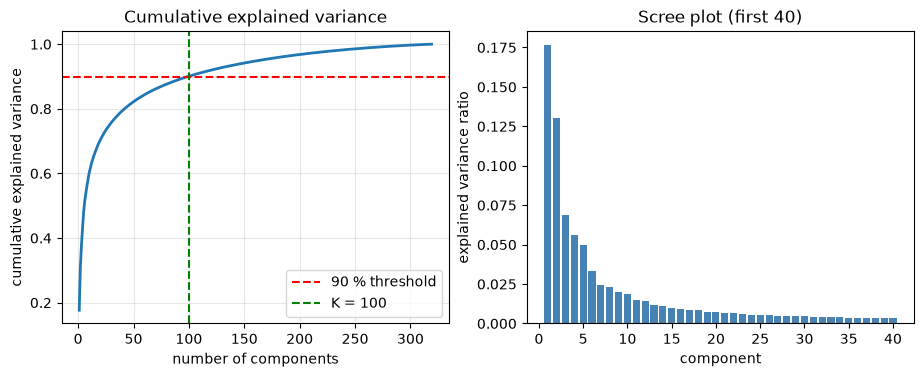

In [10]:
explained = eigvals / eigvals.sum()
cum = np.cumsum(explained)
K90 = int(np.searchsorted(cum, 0.90) + 1)
print(f"Minimum components for >= 90% variance: K90 = {K90}  (actual {cum[K90-1]*100:.2f}%)")
for p in (0.80, 0.90, 0.95, 0.99):
    print(f"  {int(p*100)}% variance -> {int(np.searchsorted(cum, p)+1):3d} components")
print(f"  Dimensionality reduction: {d} -> {K90}  ({d/K90:.0f}x fewer numbers per image)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(np.arange(1, r + 1), cum, lw=2)
axes[0].axhline(0.90, color="r", ls="--", label="90 % threshold"); axes[0].axvline(K90, color="g", ls="--", label=f"K = {K90}")
axes[0].set_xlabel("number of components"); axes[0].set_ylabel("cumulative explained variance")
axes[0].set_title("Cumulative explained variance"); axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].bar(np.arange(1, 41), explained[:40], color="steelblue")
axes[1].set_xlabel("component"); axes[1].set_ylabel("explained variance ratio"); axes[1].set_title("Scree plot (first 40)")
savefig(fig, "04_explained_variance.png")

### B4. Eigenfaces

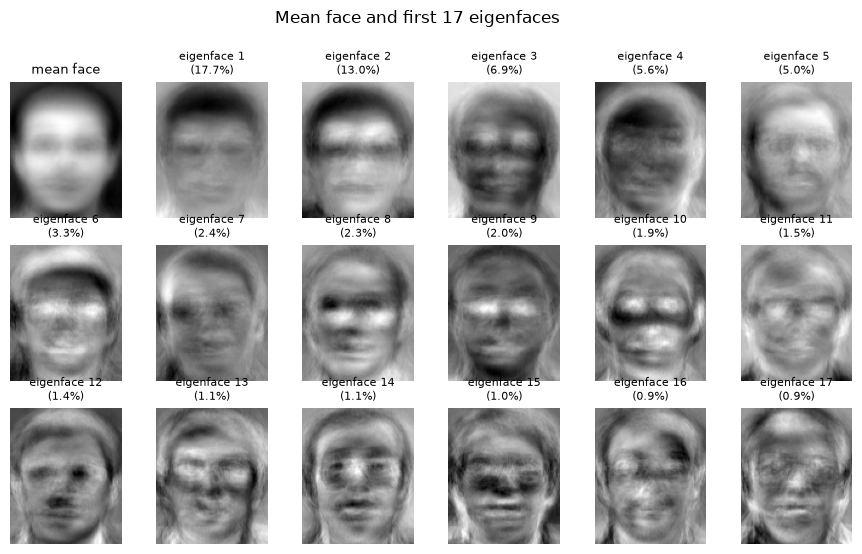

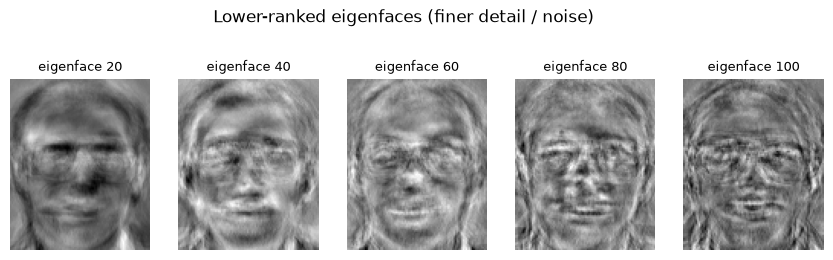

In [11]:
fig, axes = plt.subplots(3, 6, figsize=(11, 6))
axes[0, 0].imshow(mean_face.reshape(H, Wd)); axes[0, 0].set_title("mean face", fontsize=9)
for i, ax in enumerate(axes.ravel()[1:]):
    ax.imshow(W[:, i].reshape(H, Wd)); ax.set_title(f"eigenface {i+1}\n({explained[i]*100:.1f}%)", fontsize=8)
for ax in axes.ravel(): ax.axis("off")
fig.suptitle("Mean face and first 17 eigenfaces", y=1.0); savefig(fig, "05_eigenfaces_top.png")

pick = [i for i in (20, 40, 60, 80, 100, K90) if i <= r]
pick = sorted(set(pick))
fig, axes = plt.subplots(1, len(pick), figsize=(2.1 * len(pick), 2.8))
for ax, i in zip(np.atleast_1d(axes), pick):
    ax.imshow(W[:, i - 1].reshape(H, Wd)); ax.set_title(f"eigenface {i}", fontsize=9); ax.axis("off")
fig.suptitle("Lower-ranked eigenfaces (finer detail / noise)", y=1.05); savefig(fig, "06_eigenfaces_later.png")

### B5. Projection, stored reduced representation and reconstruction
Projection: `z = (x - mean) W_k`. Reconstruction: `x_hat = mean + z W_k^T`.

In [12]:
Wk = W[:, :K90]
Z_train = A @ Wk
Z_test = (X_test - mean_face) @ Wk
np.savez_compressed(RES_DIR / f"pca_model_K{K90}.npz", mean_face=mean_face, components=Wk,
                    Z_train=Z_train, y_train=y_train, Z_test=Z_test, y_test=y_test)
print("Reduced training matrix:", Z_train.shape, "  reduced test matrix:", Z_test.shape)

# full-rank projections so that any k can be sliced cheaply later
Zfull_train = A @ W
Zfull_test = (X_test - mean_face) @ W

def reconstruct(Zfull, k):
    return Zfull[:, :k] @ W[:, :k].T + mean_face

def mse_psnr(orig, rec):
    mse = np.mean((orig - rec) ** 2, axis=1)
    return mse.mean(), np.mean(10 * np.log10(1.0 / mse))

# ---- storage comparison
orig_vals = n * d
red_vals = n * K90 + K90 * d + d          # scores + basis + mean face
print(f"\nStorage (training set, {n} images):")
print(f"  original pixels : {orig_vals:>10,d} numbers = {X_train.nbytes/1e6:6.2f} MB (float64)")
print(f"  PCA (K={K90})    : {red_vals:>10,d} numbers = {(Z_train.nbytes+Wk.nbytes+mean_face.nbytes)/1e6:6.2f} MB (scores + basis + mean)")
print(f"  ratio           : {orig_vals/red_vals:.2f}x smaller overall")
print(f"  per image (once basis is shared): {d} -> {K90} numbers = {d/K90:.0f}x smaller")

# ---- quality vs k
rows = []
for k in sorted(set([1, 5, 10, 20, 50, 100, 150, K90, r])):
    if k > r: continue
    mse, psnr = mse_psnr(X_test, reconstruct(Zfull_test, k))
    rows.append(dict(k=k, variance_kept_pct=round(cum[k-1]*100, 2), test_MSE=round(mse, 5), test_PSNR_dB=round(psnr, 2),
                     numbers_per_image=k, per_image_compression=round(d / k, 1),
                     train_set_storage_ratio=round(orig_vals / (n*k + k*d + d), 2)))
recon_table = pd.DataFrame(rows).drop_duplicates("k")
recon_table.to_csv(RES_DIR / "reconstruction_quality.csv", index=False)
recon_table

Reduced training matrix: (320, 100)   reduced test matrix: (80, 100)

Storage (training set, 320 images):
  original pixels :  3,297,280 numbers =  26.38 MB (float64)
  PCA (K=100)    :  1,072,704 numbers =   8.58 MB (scores + basis + mean)
  ratio           : 3.07x smaller overall
  per image (once basis is shared): 10304 -> 100 numbers = 103x smaller


,k,variance_kept_pct,test_MSE,test_PSNR_dB,numbers_per_image,per_image_compression,train_set_storage_ratio
0,1,17.67,0.01982,17.24,1,10304.0,157.55
1,5,48.18,0.01272,19.12,5,2060.8,51.99
2,10,60.16,0.01009,20.11,10,1030.4,28.29
3,20,70.36,0.00801,21.13,20,515.2,14.80
4,50,82.20,0.00586,22.52,50,206.1,6.09
5,100,90.09,0.00483,23.39,100,103.0,3.07
6,150,94.18,0.00440,23.82,150,68.7,2.06
7,319,100.00,0.00373,24.60,319,32.3,0.97


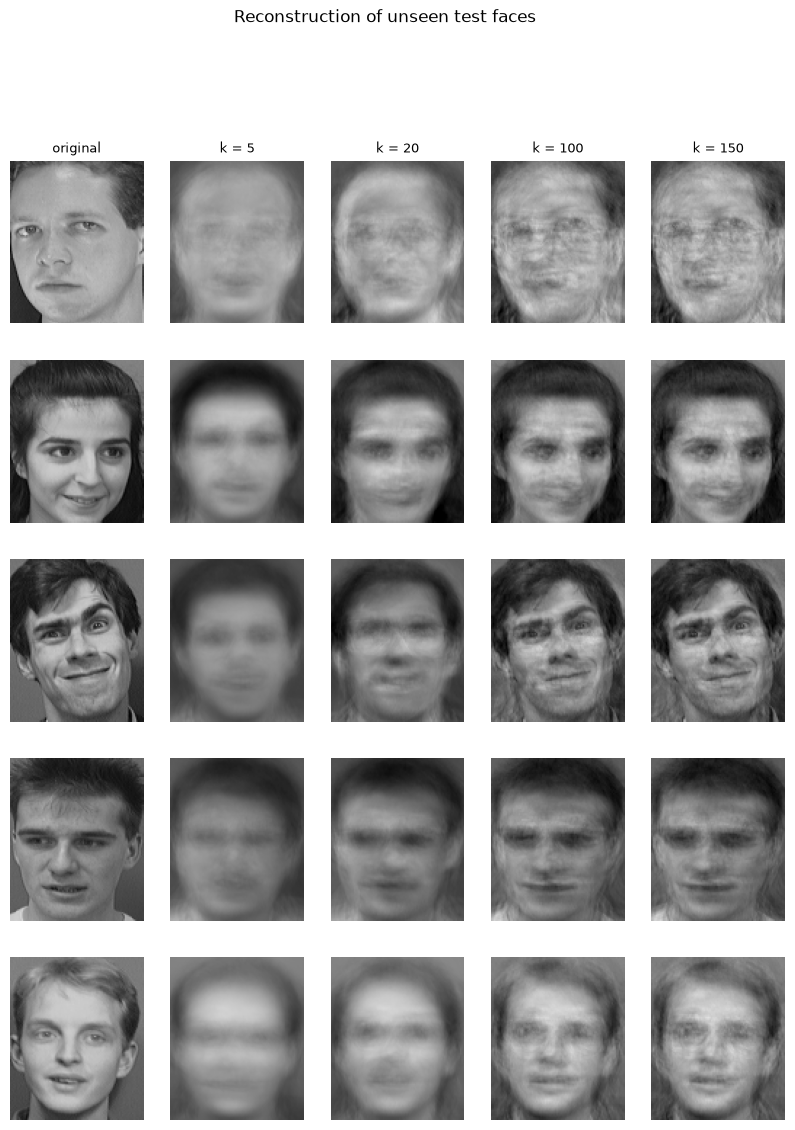

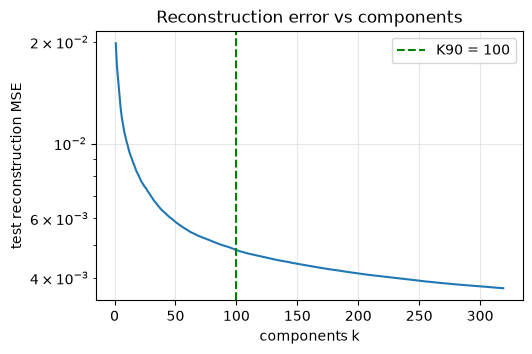

In [13]:
sample = np.linspace(0, len(X_test) - 1, 5).astype(int)
ks_show = [5, 20, K90, min(150, r)]
fig, axes = plt.subplots(len(sample), 1 + len(ks_show), figsize=(2.0 * (1 + len(ks_show)), 2.5 * len(sample)))
for row, s in enumerate(sample):
    axes[row, 0].imshow(X_test[s].reshape(H, Wd), vmin=0, vmax=1); axes[row, 0].set_title("original" if row == 0 else "", fontsize=9)
    for col, k in enumerate(ks_show, start=1):
        rec = reconstruct(Zfull_test[s:s+1], k)[0]
        axes[row, col].imshow(np.clip(rec, 0, 1).reshape(H, Wd), vmin=0, vmax=1)
        if row == 0: axes[row, col].set_title(f"k = {k}", fontsize=9)
for ax in axes.ravel(): ax.axis("off")
fig.suptitle("Reconstruction of unseen test faces", y=1.0); savefig(fig, "07_reconstructions.png")

fig, ax = plt.subplots(figsize=(5.5, 3.5))
kk = np.arange(1, r + 1)
mse_k = [mse_psnr(X_test, reconstruct(Zfull_test, k))[0] for k in kk]
ax.plot(kk, mse_k); ax.axvline(K90, color="g", ls="--", label=f"K90 = {K90}")
ax.set_xlabel("components k"); ax.set_ylabel("test reconstruction MSE"); ax.set_yscale("log"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("Reconstruction error vs components"); savefig(fig, "08_reconstruction_error_vs_k.png")

## Part C - Recognition in PCA space (similarity matching)
Each test face is projected with the *training* mean and basis, then matched to the closest stored training face (1-nearest-neighbour, Euclidean distance). The same matching is run on raw pixels for comparison.

In [14]:
def pairwise_dist(Q, R, metric="euclidean"):
    if metric == "euclidean":
        D2 = (Q**2).sum(1)[:, None] + (R**2).sum(1)[None, :] - 2 * Q @ R.T
        return np.sqrt(np.maximum(D2, 0))
    if metric == "cosine":
        q = Q / np.linalg.norm(Q, axis=1, keepdims=True); rr = R / np.linalg.norm(R, axis=1, keepdims=True)
        return 1 - q @ rr.T
    raise ValueError(metric)

def match(Q, R, ytr, metric="euclidean"):
    D = pairwise_dist(Q, R, metric)
    nn = D.argmin(axis=1)
    return nn, ytr[nn], D[np.arange(len(Q)), nn]

res = []
for name, (Q, R) in {"Raw pixels (%d dims)" % d: (X_test, X_train),
                     "PCA K=%d (>=90%% var)" % K90: (Z_test, Z_train)}.items():
    for metric in ("euclidean", "cosine"):
        t0 = time.perf_counter(); nn, pred, dist = match(Q, R, y_train, metric); t = time.perf_counter() - t0
        res.append(dict(representation=name, distance=metric, dims=Q.shape[1],
                        accuracy=(pred == y_test).mean(), match_time_ms=round(t * 1000, 2)))
sim_table = pd.DataFrame(res)
sim_table["accuracy_pct"] = (sim_table.accuracy * 100).round(2)
sim_table.drop(columns="accuracy").to_csv(RES_DIR / "similarity_matching_results.csv", index=False)
sim_table.drop(columns="accuracy")

,representation,distance,dims,match_time_ms,accuracy_pct
0,Raw pixels (10304 dims),euclidean,10304,1017.00,96.25
1,Raw pixels (10304 dims),cosine,10304,727.31,96.25
2,PCA K=100 (>=90% var),euclidean,100,0.68,96.25
3,PCA K=100 (>=90% var),cosine,100,0.75,96.25


Raw-pixel  Euclidean 1-NN accuracy : 96.25%  (77/80)
PCA (K=100) Euclidean 1-NN accuracy: 96.25%  (77/80)
Test images where the two disagree  : 0


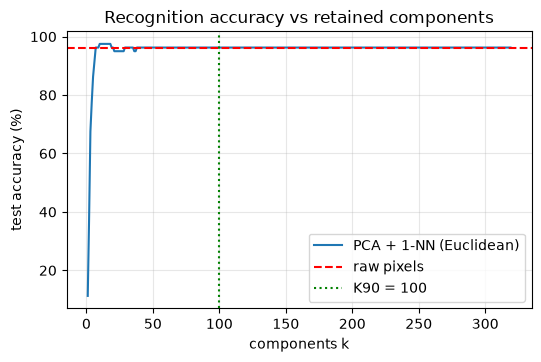

Best k for 1-NN: 10 (97.50%) ; smallest k reaching >= raw accuracy: [7]


In [15]:
# main PCA result: Euclidean 1-NN
nn_pca, pred_pca, dist_pca = match(Z_test, Z_train, y_train, "euclidean")
nn_raw, pred_raw, dist_raw = match(X_test, X_train, y_train, "euclidean")
acc_pca, acc_raw = (pred_pca == y_test).mean(), (pred_raw == y_test).mean()
print(f"Raw-pixel  Euclidean 1-NN accuracy : {acc_raw*100:.2f}%  ({(pred_raw==y_test).sum()}/{len(y_test)})")
print(f"PCA (K={K90}) Euclidean 1-NN accuracy: {acc_pca*100:.2f}%  ({(pred_pca==y_test).sum()}/{len(y_test)})")
print(f"Test images where the two disagree  : {(pred_pca != pred_raw).sum()}")

# accuracy as a function of number of components
accs = []
for k in range(1, r + 1):
    _, p, _ = match(Zfull_test[:, :k], Zfull_train[:, :k], y_train)
    accs.append((p == y_test).mean())
accs = np.array(accs)
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(np.arange(1, r + 1), accs * 100, label="PCA + 1-NN (Euclidean)")
ax.axhline(acc_raw * 100, color="r", ls="--", label="raw pixels")
ax.axvline(K90, color="g", ls=":", label=f"K90 = {K90}")
ax.set_xlabel("components k"); ax.set_ylabel("test accuracy (%)"); ax.grid(alpha=.3); ax.legend()
ax.set_title("Recognition accuracy vs retained components"); savefig(fig, "09_accuracy_vs_components.png")
print(f"Best k for 1-NN: {accs.argmax()+1} ({accs.max()*100:.2f}%) ; smallest k reaching >= raw accuracy: "
      f"{(np.flatnonzero(accs >= acc_raw)[:1] + 1).tolist()}")

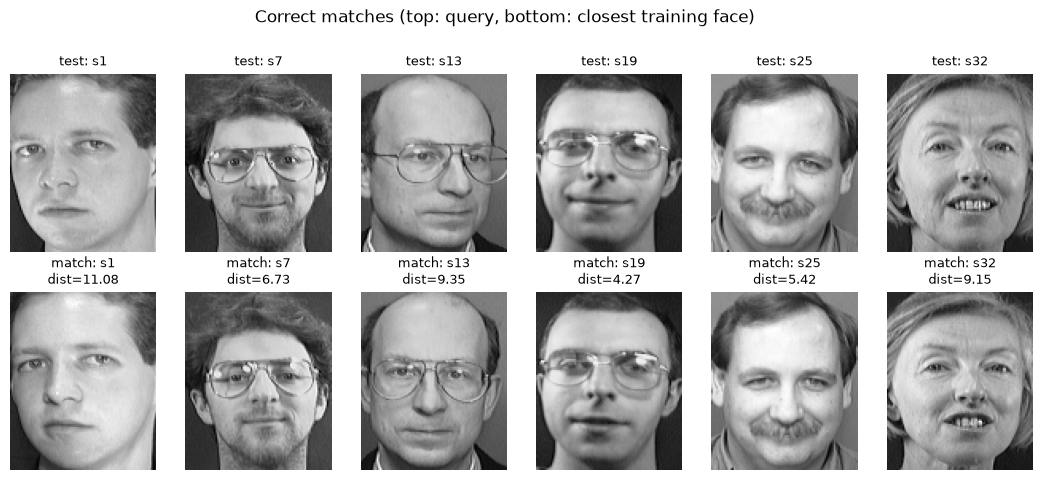

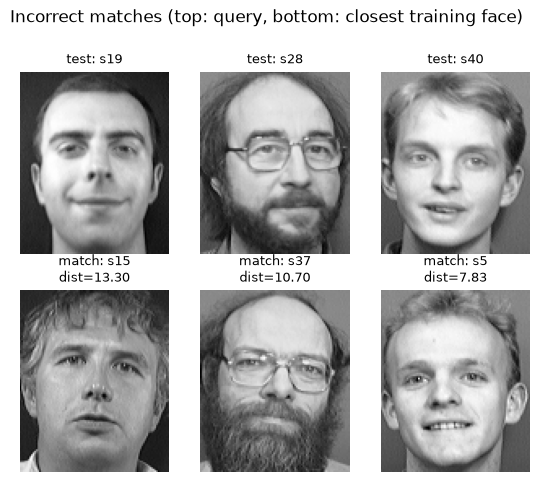

3 misclassified test images out of 80


In [16]:
def show_matches(sel, title, fname, max_n=6):
    sel = list(sel)[:max_n]
    if not sel:
        print("No examples for:", title); return
    fig, axes = plt.subplots(2, len(sel), figsize=(2.2 * len(sel), 5.2), squeeze=False)
    for c, i in enumerate(sel):
        axes[0, c].imshow(X_test[i].reshape(H, Wd)); axes[0, c].set_title(f"test: {class_names[y_test[i]]}", fontsize=9)
        j = nn_pca[i]
        axes[1, c].imshow(X_train[j].reshape(H, Wd))
        axes[1, c].set_title(f"match: {class_names[y_train[j]]}\ndist={dist_pca[i]:.2f}", fontsize=9)
        for ax in axes[:, c]: ax.axis("off")
    fig.suptitle(title, y=1.0); savefig(fig, fname)

correct = np.flatnonzero(pred_pca == y_test)
wrong = np.flatnonzero(pred_pca != y_test)
show_matches(correct[:: max(1, len(correct) // 6)], "Correct matches (top: query, bottom: closest training face)", "10_correct_matches.png")
show_matches(wrong, "Incorrect matches (top: query, bottom: closest training face)", "11_incorrect_matches.png")
print(f"{len(wrong)} misclassified test images out of {len(y_test)}")

**Why PCA matching works about as well as raw pixels:** the projection onto the leading eigenfaces is (approximately) distance-preserving for the directions that carry most of the variance, so Euclidean distances in the K-dimensional space are close to the raw-pixel distances, but with ~K/d of the computation and storage, and with a lot of pixel-level noise discarded.

## Part D - Traditional machine learning on PCA features
Scikit-learn is used **only** here. The PCA step itself is still our NumPy implementation, wrapped in a tiny scikit-learn-compatible transformer (`NumpyPCA`) so that it can be *re-fitted inside every cross-validation fold* - this avoids leaking validation faces into the PCA basis. Models are tuned with 4-fold stratified CV on the **training set only**; the test set is touched once per final model.

Searched: number of components `k`, optional whitening of the PCA scores, and each model's own hyper-parameters (KNN, Logistic Regression, linear SVM, RBF SVM).

In [17]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

class NumpyPCA(BaseEstimator, TransformerMixin):
    """PCA implemented with NumPy linear algebra only (no sklearn.decomposition)."""
    def __init__(self, n_components=50, whiten=False):
        self.n_components = n_components; self.whiten = whiten
    def fit(self, X, y=None):
        self.mean_ = X.mean(axis=0)
        Ac = X - self.mean_
        ev, V = np.linalg.eigh(Ac @ Ac.T)               # small n x n Gram matrix (same maths as SVD, much cheaper)
        ev, V = ev[::-1], V[:, ::-1]
        k = min(self.n_components, len(X) - 1)
        S = np.sqrt(np.maximum(ev[:k], 1e-12))          # singular values
        self.components_ = ((Ac.T @ V[:, :k]) / S).T    # k x d, unit-norm principal directions
        self.scale_ = S / np.sqrt(len(X) - 1)
        return self
    def transform(self, X):
        Z = (X - self.mean_) @ self.components_.T
        return Z / self.scale_ if self.whiten else Z

# sanity: our transformer reproduces the Part B projection (up to sign)
chk = NumpyPCA(K90).fit(X_train).transform(X_test)
print("max |abs(Z_sklearn-wrapper) - abs(Z_partB)| =", np.abs(np.abs(chk) - np.abs(Z_test)).max())

max |abs(Z_sklearn-wrapper) - abs(Z_partB)| = 5.088152121857092e-13


In [18]:
KS = sorted(set([10, 20, 30, 40, 60, 80, 100, 150, K90]))
KS = [k for k in KS if k <= 200]
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)
base_grid = {"pca__n_components": KS, "pca__whiten": [False, True]}

models = {
    "KNN":                  (KNeighborsClassifier(),
                             {"clf__n_neighbors": [1, 3, 5], "clf__weights": ["uniform", "distance"]}),
    "Logistic Regression":  (LogisticRegression(max_iter=3000),
                             {"clf__C": [0.1, 1, 10, 100]}),
    "SVM (linear)":         (SVC(kernel="linear"),
                             {"clf__C": [0.1, 1, 10]}),
    "SVM (RBF)":            (SVC(kernel="rbf"),
                             {"clf__C": [1, 10, 100], "clf__gamma": ["scale", "auto"]}),
}

searches, rows = {}, []
for name, (clf, grid) in models.items():
    pipe = Pipeline([("pca", NumpyPCA()), ("clf", clf)])
    gs = GridSearchCV(pipe, {**base_grid, **grid}, cv=cv, scoring="accuracy", n_jobs=-1, refit=True)
    t0 = time.perf_counter(); gs.fit(X_train, y_train); fit_t = time.perf_counter() - t0
    searches[name] = gs
    bp = gs.best_params_
    rows.append({"Model": name, "Setting": "best CV", "k": bp["pca__n_components"], "whiten": bp["pca__whiten"],
                 "params": {k.split("__")[1]: v for k, v in bp.items() if k.startswith("clf__")},
                 "CV acc (%)": round(gs.best_score_ * 100, 2),
                 "Test acc (%)": round(gs.score(X_test, y_test) * 100, 2)})
    print(f"{name:20s} best CV {gs.best_score_*100:5.2f}%  k={bp['pca__n_components']}  (grid search {fit_t:.0f}s)")

KNN                  best CV 95.00%  k=150  (grid search 46s)
Logistic Regression  best CV 98.44%  k=150  (grid search 23s)
SVM (linear)         best CV 97.81%  k=60  (grid search 17s)
SVM (RBF)            best CV 97.50%  k=60  (grid search 32s)


**Compact variant.** For each model we also pick the *smallest* `k` whose CV accuracy is within 1 percentage point of that model's best, to see how much accuracy a more compact representation costs.

In [19]:
for name, gs in searches.items():
    cvdf = pd.DataFrame(gs.cv_results_)
    cvdf["k"] = cvdf["param_pca__n_components"].astype(int)
    cand = cvdf[cvdf.mean_test_score >= cvdf.mean_test_score.max() - 0.01]
    row = cand.sort_values(["k", "mean_test_score"], ascending=[True, False]).iloc[0]
    est = clone(gs.estimator).set_params(**row["params"]).fit(X_train, y_train)
    rows.append({"Model": name, "Setting": "compact (<=1pt below best CV)", "k": int(row["k"]),
                 "whiten": row["params"]["pca__whiten"],
                 "params": {k.split("__")[1]: v for k, v in row["params"].items() if k.startswith("clf__")},
                 "CV acc (%)": round(row.mean_test_score * 100, 2),
                 "Test acc (%)": round(est.score(X_test, y_test) * 100, 2)})

# similarity-based baselines from Part C
base_rows = [
    {"Model": "1-NN Euclidean, raw pixels", "Setting": "baseline", "k": d, "whiten": "-", "params": {}, "CV acc (%)": np.nan,
     "Test acc (%)": round(acc_raw * 100, 2)},
    {"Model": f"1-NN Euclidean, PCA K90", "Setting": "baseline", "k": K90, "whiten": False, "params": {}, "CV acc (%)": np.nan,
     "Test acc (%)": round(acc_pca * 100, 2)},
]
comparison = pd.concat([pd.DataFrame(base_rows), pd.DataFrame(rows)], ignore_index=True)
comparison["params"] = comparison["params"].astype(str)
comparison.to_csv(RES_DIR / "ml_comparison.csv", index=False)

def df_to_md(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "|".join("---" for _ in cols) + "|"]
    for _, r_ in df.iterrows():
        lines.append("| " + " | ".join("" if (isinstance(v, float) and np.isnan(v)) else str(v) for v in r_.values) + " |")
    return "\n".join(lines)

(RES_DIR / "ml_comparison.md").write_text(df_to_md(comparison), encoding="utf-8")
comparison

,Model,Setting,k,whiten,params,CV acc (%),Test acc (%)
0,"1-NN Euclidean, raw pixels",baseline,10304,-,{},NaN,96.25
1,"1-NN Euclidean, PCA K90",baseline,100,False,{},NaN,96.25
2,KNN,best CV,150,False,"{'n_neighbors': 1, 'weights': 'uniform'}",95.00,96.25
3,Logistic Regression,best CV,150,False,{'C': 10},98.44,97.50
4,SVM (linear),best CV,60,True,{'C': 0.1},97.81,96.25
5,SVM (RBF),best CV,60,True,"{'C': 1, 'gamma': 'scale'}",97.50,96.25
6,KNN,compact (<=1pt below best CV),20,False,"{'n_neighbors': 1, 'weights': 'uniform'}",94.06,96.25
7,Logistic Regression,compact (<=1pt below best CV),30,False,{'C': 0.1},97.50,97.50
8,SVM (linear),compact (<=1pt below best CV),30,False,{'C': 0.1},96.88,97.50
9,SVM (RBF),compact (<=1pt below best CV),30,False,"{'C': 10, 'gamma': 'scale'}",96.88,97.50


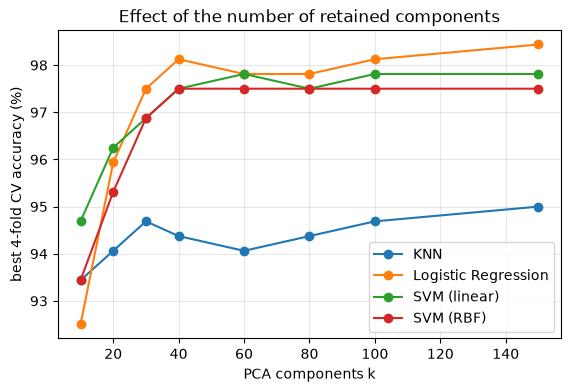

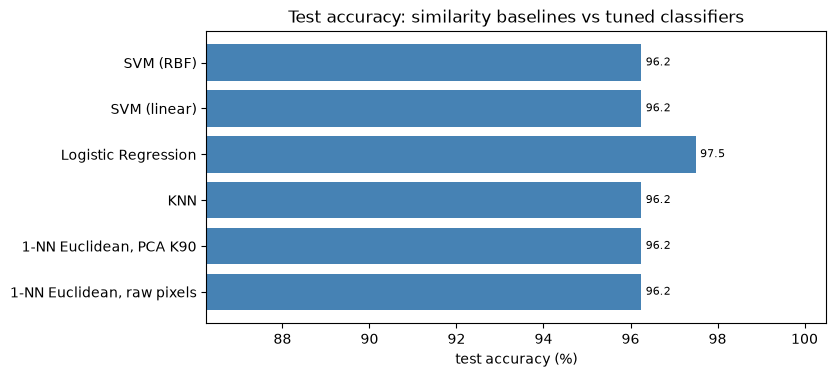

In [20]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for name, gs in searches.items():
    cvdf = pd.DataFrame(gs.cv_results_); cvdf["k"] = cvdf["param_pca__n_components"].astype(int)
    curve = cvdf.groupby("k").mean_test_score.max()
    ax.plot(curve.index, curve.values * 100, marker="o", label=name)
ax.set_xlabel("PCA components k"); ax.set_ylabel("best 4-fold CV accuracy (%)")
ax.set_title("Effect of the number of retained components"); ax.grid(alpha=.3); ax.legend()
savefig(fig, "12_ml_accuracy_vs_k.png")

fig, ax = plt.subplots(figsize=(8, 3.8))
best_rows = comparison[comparison.Setting != "compact (<=1pt below best CV)"]
ax.barh(best_rows.Model, best_rows["Test acc (%)"], color="steelblue")
ax.set_xlabel("test accuracy (%)"); ax.set_xlim(max(0, best_rows["Test acc (%)"].min() - 10), 100.5)
for i, v in enumerate(best_rows["Test acc (%)"]): ax.text(v + 0.1, i, f"{v:.1f}", va="center", fontsize=8)
ax.set_title("Test accuracy: similarity baselines vs tuned classifiers"); savefig(fig, "13_model_comparison.png")

## Summary of results (auto-generated, also saved to `results/summary.md`)

In [21]:
best_name = max(searches, key=lambda m: comparison[(comparison.Model == m) & (comparison.Setting == "best CV")]["Test acc (%)"].iloc[0])
b = comparison[(comparison.Model == best_name) & (comparison.Setting == "best CV")].iloc[0]
c = comparison[(comparison.Model == best_name) & (comparison.Setting != "best CV")].iloc[0]
summary = f"""# Results summary

* Dataset: {N} images, {len(class_names)} subjects, {H}x{Wd} px ({D} features). Split: {len(X_train)} train / {len(X_test)} test (2 test images per subject, seed {SEED}).
* PCA: {K90} components retain >= 90% variance ({cum[K90-1]*100:.2f}%), i.e. {d/K90:.0f}x fewer numbers per image. Eigendecomposition and SVD agree (max eigenvalue difference {np.abs(ev_cov-ev_svd).max():.1e}).
* Training-set storage: {orig_vals:,} numbers (raw) vs {red_vals:,} (scores + basis + mean) = {orig_vals/red_vals:.1f}x smaller.
* Reconstruction at K={K90}: test PSNR {mse_psnr(X_test, reconstruct(Zfull_test, K90))[1]:.2f} dB.
* 1-NN (Euclidean) test accuracy: raw pixels {acc_raw*100:.2f}% vs PCA K={K90} {acc_pca*100:.2f}%.
* Best traditional model: {best_name} - test accuracy {b['Test acc (%)']}% with k={b['k']} (CV {b['CV acc (%)']}%); compact version k={c['k']} gives {c['Test acc (%)']}%.

## Comparison table

{df_to_md(comparison)}
"""
(RES_DIR / "summary.md").write_text(summary, encoding="utf-8")
print(summary)

# Results summary

* Dataset: 400 images, 40 subjects, 112x92 px (10304 features). Split: 320 train / 80 test (2 test images per subject, seed 42).
* PCA: 100 components retain >= 90% variance (90.09%), i.e. 103x fewer numbers per image. Eigendecomposition and SVD agree (max eigenvalue difference 1.3e-13).
* Training-set storage: 3,297,280 numbers (raw) vs 1,072,704 (scores + basis + mean) = 3.1x smaller.
* Reconstruction at K=100: test PSNR 23.39 dB.
* 1-NN (Euclidean) test accuracy: raw pixels 96.25% vs PCA K=100 96.25%.
* Best traditional model: Logistic Regression - test accuracy 97.5% with k=150 (CV 98.44%); compact version k=30 gives 97.5%.

## Comparison table

| Model | Setting | k | whiten | params | CV acc (%) | Test acc (%) |
|---|---|---|---|---|---|---|
| 1-NN Euclidean, raw pixels | baseline | 10304 | - | {} |  | 96.25 |
| 1-NN Euclidean, PCA K90 | baseline | 100 | False | {} |  | 96.25 |
| KNN | best CV | 150 | False | {'n_neighbors': 1, 'weights': 'uniform'} | 95.0 | 96

## Observations
*(After running the notebook, check these against your own numbers in `results/summary.md`.)*

1. **Variance is concentrated.** A few dozen eigenfaces already carry most of the variance; the first ones capture global lighting / face shape, later ones capture finer detail and noise.
2. **Compression.** Keeping K90 components stores each face with over 100x fewer numbers than raw pixels, and reconstructions remain clearly recognisable; error falls quickly with k and then flattens.
3. **Recognition.** Euclidean 1-NN in PCA space performs on par with raw pixels at a fraction of the dimensionality and matching cost. Errors usually involve subjects with strong pose / expression changes between train and test images.
4. **Classifiers.** Tuned linear models and SVMs on PCA scores typically match or beat the 1-NN baseline (check your table); accuracy saturates at a modest k, so a compact representation costs little accuracy.
5. **Caveat.** The test set has only 80 images (one image = 1.25 points), so differences of a few points between models are within noise; the CV scores on the 320 training images give a second, more stable view.